# Exploratory Data Analysis (EDA) 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('../Dataset/Advertising.csv')

In [4]:
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [6]:
df.drop('Unnamed: 0',axis=1,inplace=True)

In [7]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### Initial observation:
 Newspaper and Sales have means higher than their medians. This could indicate right-skewed distributions, potentially influenced by some higher values.

Newspaper's max value is much higher than upper quartile Q3, that does not automatically mean it should be removed but must be investigated. 



In [11]:
## Interquartile Range (IQR) measures the spread of the middle 50% of the data.
Q1=df.quantile(0.25)
Q3=df.quantile(0.75)

IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

print("IQR:\n",IQR)
print("\n")
print("Lower Bound:\n",lower_bound)
print("\n")
print("Upper Bound:\n",upper_bound)

IQR:
 TV           144.450
radio         26.550
newspaper     32.350
sales          7.025
dtype: float64


Lower Bound:
 TV          -142.3000
radio        -29.8500
newspaper    -35.7750
sales         -0.1625
dtype: float64


Upper Bound:
 TV           435.5000
radio         76.3500
newspaper     93.6250
sales         27.9375
dtype: float64


In [ ]:
## identifying outliers

outliers=df[(df<lower_bound) | (df>upper_bound)] 


outliers_count=outliers.count()

print("Number of outliers:\n",outliers_count)


outliers_percentage=(outliers_count/df.shape[0])*100

print("\nPercentage of outliers:\n",outliers_percentage)


outliers.dropna(how='all')

Number of outliers:
 TV           0
radio        0
newspaper    2
sales        0
dtype: int64

Percentage of outliers:
 TV           0.0
radio        0.0
newspaper    1.0
sales        0.0
dtype: float64


,TV,radio,newspaper,sales
16,NaN,NaN,114.0,NaN
101,NaN,NaN,100.9,NaN


In [14]:
df[df["newspaper"]>upper_bound["newspaper"]]

,TV,radio,newspaper,sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


### Visualization

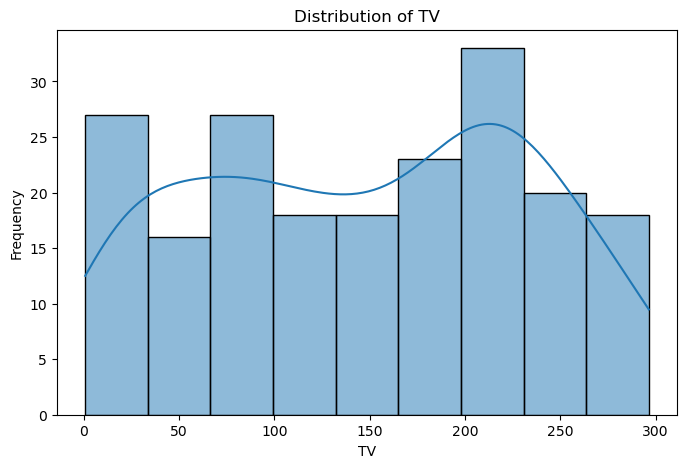

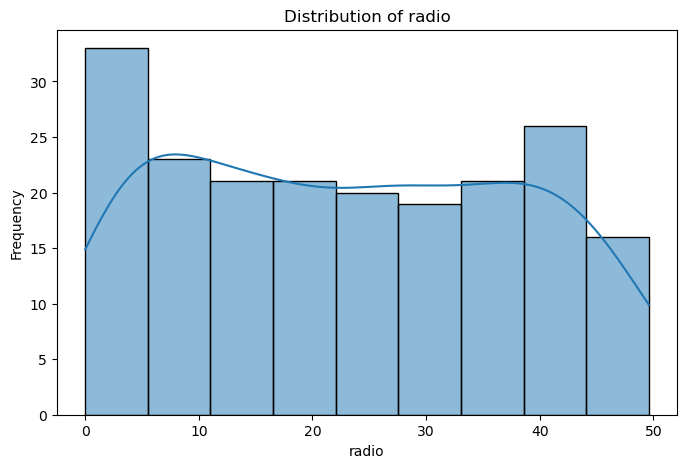

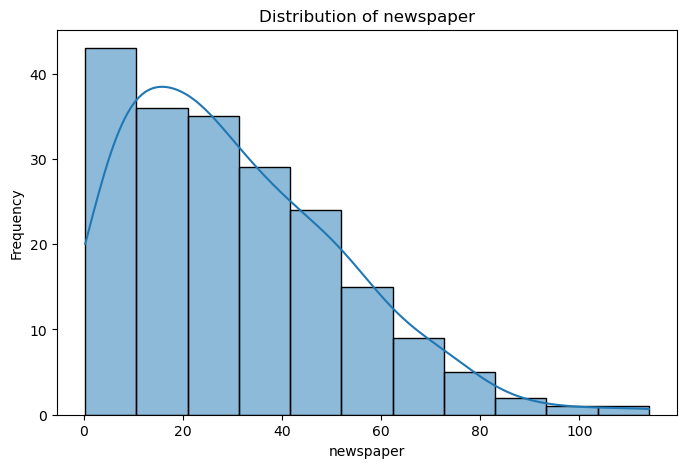

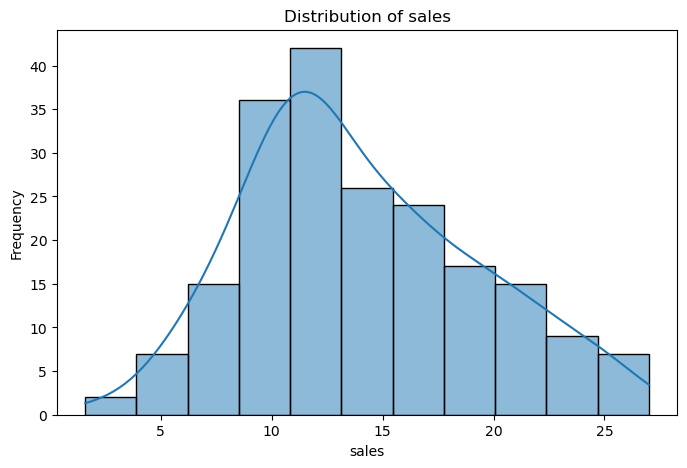

In [20]:
# Histogram 
##Distribution shape
##frequency of observations
##skewness
##concentration of values

for col in df.columns:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df,x=col,kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()



### Interpretations:

 - sales and newpapers are right skewed where newspaper has long tail towards the increasing values showing strong right skewness whill sales shows mild right skewness.

 - TV and radio are relatively spread spread out.

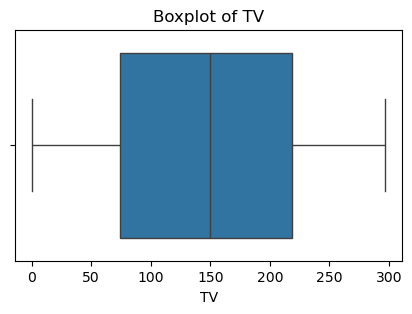

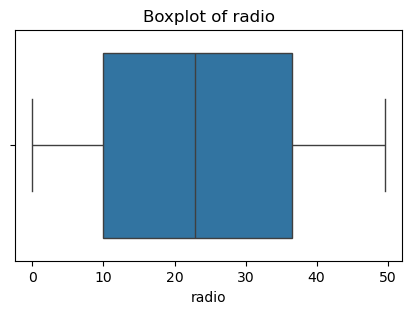

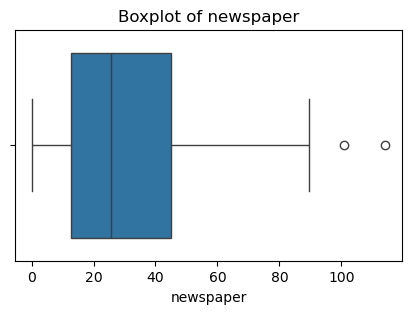

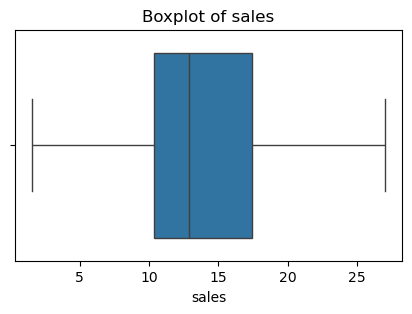

In [23]:
# Boxplot

for col in df.columns:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


### Boxplot Observations

- Newspaper contains potential outliers beyond the upper IQR boundary.
- TV, Radio and Sales do not have observations outside their calculated IQR boundaries.
- The Newspaper outlier will be retained pending further investigation.

In [24]:
df[df["newspaper"] > upper_bound["newspaper"]]

,TV,radio,newspaper,sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


### Newspaper Outlier Investigation

The IQR method identified two potential outlier observations
in the Newspaper advertising expenditure variable.

| Row | Newspaper | Sales |
|---|---:|---:|
| 16 | 114.0 | 12.5 |
| 101 | 100.9 | 23.8 |

Both observations exceed the upper IQR boundary of 93.625.

These observations are retained because they may represent
genuine advertising expenditure. Their influence will be
evaluated during regression diagnostics.